<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/notebooks/G01_U3.2_poly_regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 3.2: Polynomial and Regularised Regression

- **Registration number:** COM/0032/23
- **owner:** Abdul Razak (Member 4)
- **Module:** 4

**Contents**
1. Setup and data loading
2. Polynomial regression
3. Ridge and lasso
4. Comparison of all regression models
5. Written answer

In [17]:
# Mount Drive, import libraries and load the cleaned data from Task 2.2
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_clean = pd.read_csv("/content/drive/MyDrive/CSC4110_G01/data/clean_students.csv")
out = "/content/drive/MyDrive/CSC4110_G01/outputs/"

# Same split and scaler as Task 3.1
X = df_clean.drop(columns=['Exam_Score', 'high_score'])
y = df_clean['Exam_Score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

# Helper: RMSE in marks
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(5285, 22) (1322, 22)


In [18]:
# Hours_Studied alone, as a one-column table
hours_train = X_train[['Hours_Studied']]
hours_test = X_test[['Hours_Studied']]

# A pipeline chains steps: scale -> add polynomial terms -> fit a line
# The scaler inside it learns from the training data only
def poly_pipeline(degree):
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(degree, include_bias=False),
                         LinearRegression())

poly_results = {}
poly_models = {}
for degree in [1, 2, 3]:
    model = poly_pipeline(degree).fit(hours_train, y_train)
    poly_models[degree] = model
    poly_results[degree] = {'train_rmse': rmse(y_train, model.predict(hours_train)),
                            'test_rmse': rmse(y_test, model.predict(hours_test))}
print(pd.DataFrame(poly_results).T.round(4))

   train_rmse  test_rmse
1      3.5268     3.2948
2      3.5262     3.2932
3      3.5262     3.2930


degree 1: train RMSE = 3.5268, test RMSE = 3.2948
degree 3: train RMSE = 3.5262, test RMSE = 3.2930
degree 10: train RMSE = 3.5151, test RMSE = 3.2972


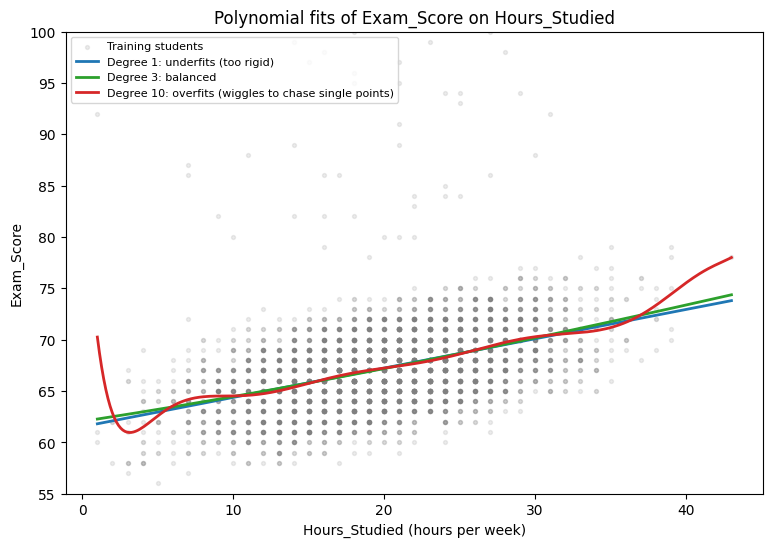

In [19]:
# Fit degree 1, 3 and 10 and print their errors
curve_models = {d: poly_pipeline(d).fit(hours_train, y_train) for d in [1, 3, 10]}
for d, m in curve_models.items():
    print(f"degree {d}: train RMSE = {rmse(y_train, m.predict(hours_train)):.4f}, "
          f"test RMSE = {rmse(y_test, m.predict(hours_test)):.4f}")

# Smooth grid of hours so the curves draw as lines
grid = pd.DataFrame({'Hours_Studied': np.linspace(hours_train['Hours_Studied'].min(),
                                                  hours_train['Hours_Studied'].max(), 300)})
plt.figure(figsize=(9, 6))
plt.scatter(hours_train, y_train, alpha=0.15, s=8, color='grey', label='Training students')
styles = {1: ('tab:blue', 'Degree 1: underfits (too rigid)'),
          3: ('tab:green', 'Degree 3: balanced'),
          10: ('tab:red', 'Degree 10: overfits (wiggles to chase single points)')}
for d, (colour, label) in styles.items():
    plt.plot(grid, curve_models[d].predict(grid), color=colour, linewidth=2, label=label)
plt.ylim(55, 100)
plt.title('Polynomial fits of Exam_Score on Hours_Studied')
plt.xlabel('Hours_Studied (hours per week)')
plt.ylabel('Exam_Score')
plt.legend(loc='upper left', fontsize=8)
plt.savefig(out + 'under_over_fit.png', dpi=150, bbox_inches='tight')
plt.show()

### Polynomial Complexity: Underfitting vs. Overfitting Analysis

**Underfitting (`Degree 1`):** A straight line forces a strictly constant rate of score improvement across all study hours, making it slightly too rigid to capture subtle curvature at the extremes:
- **Evidence:** `Degree 1` produces the highest training RMSE (`3.5268`) and a slightly higher test RMSE (`3.2948`) than the smooth cubic curve (`Degree 3`: train `3.5262`, test `3.2930`).

**Overfitting (`Degree 10`):** With 10 polynomial terms, the model gains excessive flexibility and begins chasing random noise among sparse extreme observations rather than the true underlying trend:
- **Numerical Evidence:** `Degree 10` achieves the lowest training RMSE (`3.5151`) yet degrades to the worst test RMSE (`3.2972`) among the three models—the classic overfitting signature where lower training error fails to generalize.
- **Visual Evidence:** On the plot, the dense core of `5,285` training students anchors the middle of the red curve firmly in place, keeping the overfitting mild; however, at the sparsely populated tails, the red curve bends into an artificial dip between `1–5` hours and curls sharply upward past `38` hours to chase a handful of extreme students (pushing complexity further to `Degree 15` exaggerates this tail instability dramatically, sending test RMSE spiking to `~14.9`).

Therefore, `Degree 3` strikes the cleanest bias–variance balance—capturing the genuine trend without bending to noise in the tails—while using only `Hours_Studied` confirms that single-feature polynomial curves remain far less accurate than multi-feature models.

In [20]:
alphas = [0.01, 0.1, 1, 10]
ridge_results, lasso_results, lasso_zeros = {}, {}, {}
ridge_models, lasso_models = {}, {}
for a in alphas:
    ridge = Ridge(alpha=a).fit(X_train_scaled, y_train)
    lasso = Lasso(alpha=a, max_iter=10000).fit(X_train_scaled, y_train)
    ridge_models[a], lasso_models[a] = ridge, lasso
    ridge_results[a] = rmse(y_test, ridge.predict(X_test_scaled))
    lasso_results[a] = rmse(y_test, lasso.predict(X_test_scaled))
    lasso_zeros[a] = int((lasso.coef_ == 0).sum())      # coefficients exactly zero
print(pd.DataFrame({'ridge_test_rmse': ridge_results,
                    'lasso_test_rmse': lasso_results,
                    'lasso_zero_coefs': lasso_zeros}).round(4))

       ridge_test_rmse  lasso_test_rmse  lasso_zero_coefs
0.01            1.7984           1.7976                 2
0.10            1.7984           1.8369                 6
1.00            1.7983           2.6948                20
10.00           1.7982           3.7611                22


In [21]:
# Re-fit the multiple linear regression from Task 3.1 on the same split
lr_multi = LinearRegression().fit(X_train_scaled, y_train)

# Pick the best of each family by test RMSE
best_degree = min(poly_results, key=lambda d: poly_results[d]['test_rmse'])
best_ridge = min(ridge_results, key=ridge_results.get)
best_lasso = min(lasso_results, key=lasso_results.get)

test_preds = {'Linear': lr_multi.predict(X_test_scaled),
              f'Polynomial (degree {best_degree})': poly_models[best_degree].predict(hours_test),
              f'Ridge (alpha={best_ridge})': ridge_models[best_ridge].predict(X_test_scaled),
              f'Lasso (alpha={best_lasso})': lasso_models[best_lasso].predict(X_test_scaled)}

results_reg = pd.DataFrame({name: {'MAE': mean_absolute_error(y_test, p),
                                   'RMSE': rmse(y_test, p),
                                   'R2': r2_score(y_test, p)}
                            for name, p in test_preds.items()}).T
print(results_reg.round(4))

# Training RMSE of the same four models, for the overfitting comparison
train_rmse_check = {'Linear': rmse(y_train, lr_multi.predict(X_train_scaled)),
                    'Polynomial': poly_results[best_degree]['train_rmse'],
                    'Ridge': rmse(y_train, ridge_models[best_ridge].predict(X_train_scaled)),
                    'Lasso': rmse(y_train, lasso_models[best_lasso].predict(X_train_scaled))}
print({k: round(v, 4) for k, v in train_rmse_check.items()})

                          MAE    RMSE      R2
Linear                 0.4451  1.7984  0.7712
Polynomial (degree 3)  2.4445  3.2930  0.2328
Ridge (alpha=10)       0.4473  1.7982  0.7712
Lasso (alpha=0.01)     0.4481  1.7976  0.7714
{'Linear': 2.0837, 'Polynomial': 3.5262, 'Ridge': 2.0838, 'Lasso': 2.0843}


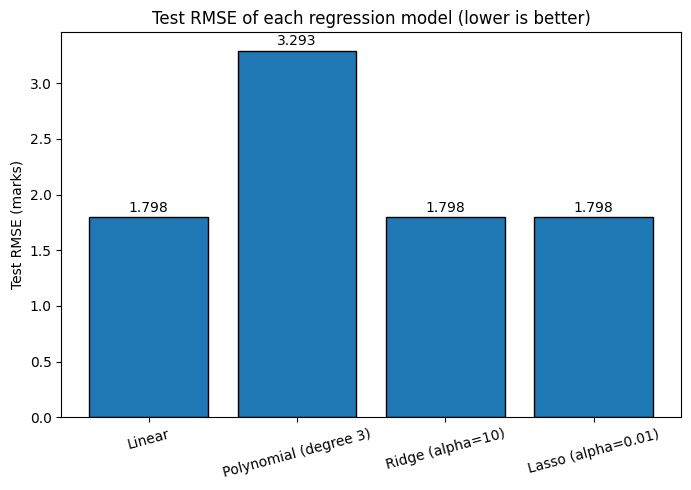

In [22]:
plt.figure(figsize=(8, 5))
plt.bar(results_reg.index, results_reg['RMSE'], edgecolor='black')
for i, v in enumerate(results_reg['RMSE']):
    plt.text(i, v + 0.05, f'{v:.3f}', ha='center')
plt.title('Test RMSE of each regression model (lower is better)')
plt.ylabel('Test RMSE (marks)')
plt.xticks(rotation=15)
plt.savefig(out + 'regression_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
lasso_alpha1 = pd.Series(lasso_models[1].coef_, index=X_train.columns)
print("Set to zero:", list(lasso_alpha1[lasso_alpha1 == 0].index))
print("Kept:\n", lasso_alpha1[lasso_alpha1 != 0].round(4))

Set to zero: ['Hours_Studied', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'School_Type_Private', 'School_Type_Public', 'Gender_Female', 'Gender_Male']
Kept:
 Attendance    0.7661
effort        1.1952
dtype: float64


In [24]:
assert X_train.shape == (5285, 22) and X_test.shape == (1322, 22)
assert set(poly_results) == {1, 2, 3}
assert set(ridge_results) == set(lasso_results) == set(alphas)
assert list(results_reg.columns) == ['MAE', 'RMSE', 'R2'] and len(results_reg) == 4
print("Task 3.2 checks passed")

Task 3.2 checks passed


### Regularization, Polynomial Complexity, and Model Comparison

**1. Model Comparison & Key Takeaways:**
- **Best Model:** While Lasso ($\alpha = 0.01$) achieves the lowest test RMSE at `1.7976`, standard Linear Regression (`1.7984`) and Ridge (`1.7982`) are practically tied—the differences appear only in the fourth decimal place, meaning **all three multi-feature models are effectively equivalent**. By contrast, the single-feature Polynomial model performs far worse (test RMSE `3.2930`, $R^2 = 0.23$) because one predictor alone cannot capture the rest of the student factors.
- **Overfitting Assessment:** None of the multi-feature models overfit; in fact, test RMSE is slightly lower than training RMSE across all four main models (e.g., `1.80` vs. `2.08` for Linear Regression). The only clear overfitting signal appears in the **degree-10 polynomial** on a single feature, which achieves the lowest training error by twisting to fit noise while performing worst on unseen test data.
- **Features That Matter:** `Attendance` and `Hours_Studied` (captured jointly through `effort`) are the dominant drivers of `Exam_Score`, followed by `Access_to_Resources`, `Previous_Scores`, and `Parental_Involvement`. Increasing Lasso's penalty to $\alpha = 1$ = 1 is too strong: it raised test RMSE from 1.80 to 2.69 by dropping useful predictors: Lasso drops correlated features arbitrarily, so an eliminated variable may simply overlap with a retained one rather than being genuinely unimportant.

**2. Conceptual Check:**
- **Why Ridge Changes Little (`alpha = 0.01` to `10`) While Lasso Degrades:** Because our features are standardized and sample size is large ($n \approx 5,285$ training rows), an $L_2$ penalty of $\alpha = 10$ applies only gentle proportional shrinkage across all weights without zeroing any out. By contrast, Lasso's $L_1$ penalty imposes a constant slope penalty regardless of weight size, aggressively pushing real predictive coefficients straight to `0` once $\alpha$ grows large—causing severe underfitting.
- **Why Degree 10 Fits Training Data Better Than Degree 3 Yet Scores Worse on Test Data:** A degree-10 curve has far more flexibility (degrees of freedom), allowing it to wiggle through random noise and sample-specific quirks in the training set. Those high-frequency wiggles do not exist in new students, causing wild interpolations and worse test predictions (classic high-variance overfitting).
- **Why a Feature Zeroed by Lasso Is Not Necessarily Useless:** When two or more features are correlated (for example, `effort`, `Attendance`, and `Hours_Studied`), Lasso tends to keep one and force the redundant partner's coefficient to `0` to minimize the $L_1$ sum. A zeroed feature may still be strongly predictive on its own—it simply shares overlapping information with a feature already selected by the model.